# 03 — Carte des stations Citiz en France

**Objectif** : voir où sont les stations Citiz, et combien il y en a par région et par département.

**Notions utilisées**
- **WGS84 (EPSG:4326)** : les coordonnées latitude / longitude en degrés, celles des flux GBFS.
- **Lambert 93 (EPSG:2154)** : la projection officielle de la France métropolitaine, en mètres. On l'utilise pour dessiner la carte et pour tout calcul de distance (5 min à pied ≈ 400 m).
- **Jointure spatiale** : rattacher chaque point au polygone (département, région) qui le contient.

**Fond de carte** : contours simplifiés des régions et départements (dérivés d'IGN Admin Express, dépôt `gregoiredavid/france-geojson`). Ils suffisent pour une vue nationale ; les contours officiels détaillés sont préparés dans `ign-osm/`.

**Sorties** dans `citiz/data/processed/` :
- `citiz_stations_map.png` : carte statique, pour les slides ;
- `citiz_stations_map.html` : carte interactive, à ouvrir dans un navigateur pour la démo ;
- `citiz_stations_by_department.png` : nombre de stations par département ;
- `citiz_stations_geo.csv` : stations avec leur département et leur région.

In [1]:
from pathlib import Path

current_directory = Path.cwd().resolve()
project_directory = None
for directory in [current_directory, *current_directory.parents]:
    if (directory / "citiz" / "AGENTS.md").exists():
        project_directory = directory
        break
if project_directory is None:
    raise FileNotFoundError("Open this notebook from the repository directory.")

module_directory = project_directory / "citiz"
gbfs_directory = module_directory / "data" / "raw" / "gbfs"
boundaries_directory = module_directory / "data" / "raw" / "boundaries"
processed_directory = module_directory / "data" / "processed"
for directory in [gbfs_directory, boundaries_directory, processed_directory]:
    directory.mkdir(parents=True, exist_ok=True)

import shutil
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster

ID_COLUMNS = {"station_id": "string", "vehicle_type_id": "string", "post_code": "string"}


def read_gbfs_csv(file_name):
    """Read a raw CSV, keeping identifiers as text ("01" must not become 1)."""
    return pd.read_csv(gbfs_directory / file_name, dtype=ID_COLUMNS)


BOUNDARY_URLS = {
    "regions": "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/regions-version-simplifiee.geojson",
    "departements": "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson",
}


def load_boundaries(name):
    """Download the simplified GeoJSON once, then read the local copy."""
    path = boundaries_directory / f"{name}.geojson"
    if not path.exists():
        response = requests.get(BOUNDARY_URLS[name], timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
    return gpd.read_file(path)

## 1. Stations → points géographiques

Le nom lisible du réseau (Grand Est, AURA, Lyon…) vient de `citiz_flux.csv`.

In [2]:
stations = read_gbfs_csv("citiz_stations.csv")
feeds = read_gbfs_csv("citiz_flux.csv")

network_names = feeds.set_index("source").dataset_title.str.replace("Autopartage Citiz ", "", regex=False)
stations["reseau"] = stations.source.map(network_names).fillna(stations.source)

station_points = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(stations.lon, stations.lat), crs="EPSG:4326")
print(f"{len(station_points)} stations, {station_points.reseau.nunique()} networks")
station_points.groupby("reseau").size().sort_values(ascending=False)

1615 stations, 15 networks


reseau
Auvergne Rhône Alpes (AURA)    412
Grand Est                      290
Métropole de Lyon              200
Occitanie                      142
Gironde                        100
Provence                        97
Haut de France                  80
Rennes Métropole                66
Développement                   64
Bourgogne Franche-Comté BFC     60
Angers Loire Métropole          28
La Rochelle                     24
Nantes Métropole                23
Grand Poitiers                  21
Pays Basque AUPA                 8
dtype: int64

## 2. Contours des régions et départements

In [3]:
regions = load_boundaries("regions")
departments = load_boundaries("departements")
print(f"{len(regions)} regions, {len(departments)} departments")

13 regions, 96 departments


## 3. Carte statique

Couleur = réseau Citiz ; taille du point = capacité de la station.

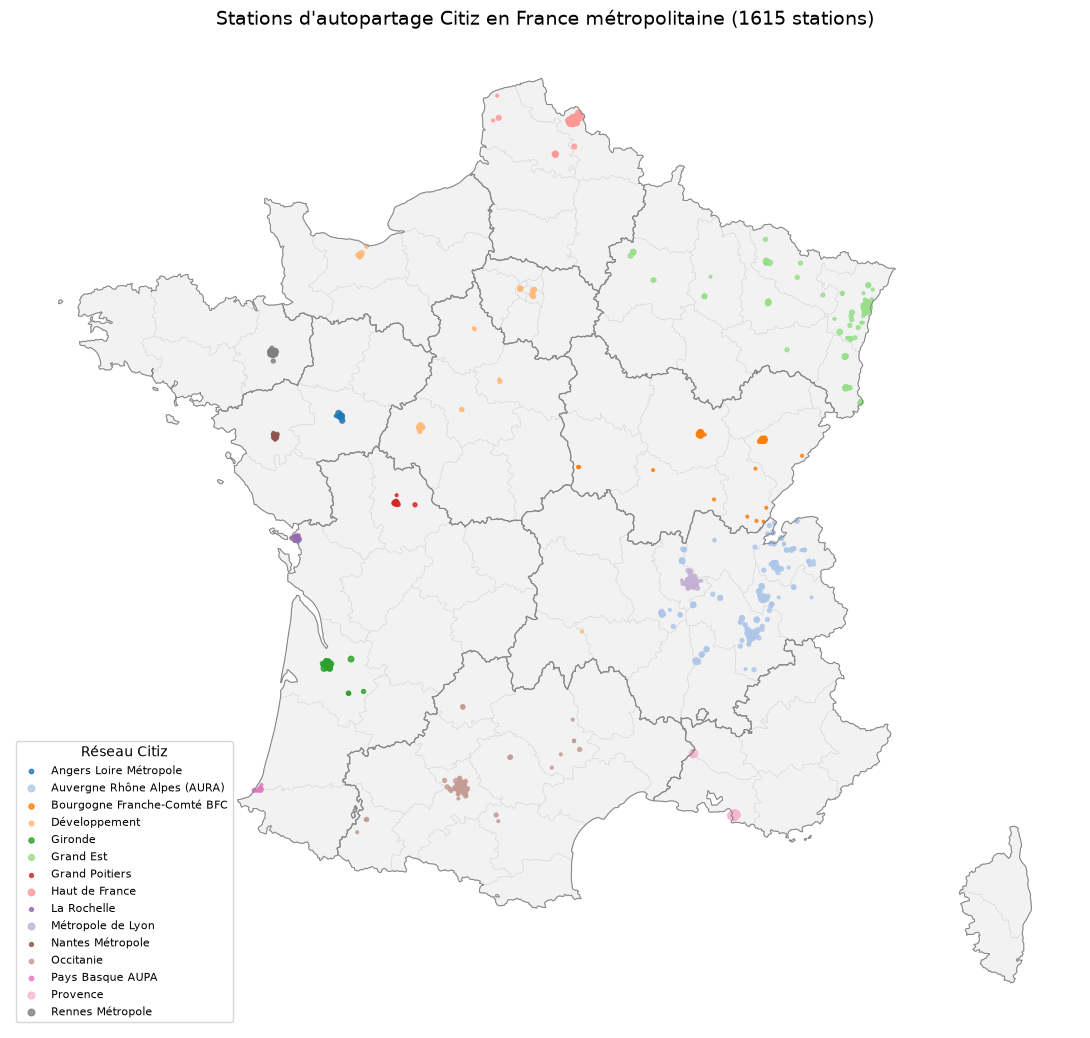

In [4]:
LAMBERT_93 = "EPSG:2154"
regions_l93 = regions.to_crs(LAMBERT_93)
departments_l93 = departments.to_crs(LAMBERT_93)
stations_l93 = station_points.to_crs(LAMBERT_93)

fig, ax = plt.subplots(figsize=(11, 11))
departments_l93.plot(ax=ax, color="#f2f2f2", edgecolor="#d0d0d0", linewidth=0.3)
regions_l93.boundary.plot(ax=ax, color="#888888", linewidth=0.8)
stations_l93.plot(ax=ax, column="reseau", categorical=True, cmap="tab20",
                  markersize=stations_l93.capacity.fillna(1).clip(1, 10) * 4, alpha=0.8,
                  legend=True, legend_kwds={"loc": "lower left", "fontsize": 8, "title": "Réseau Citiz"})
ax.set_title(f"Stations d'autopartage Citiz en France métropolitaine ({len(stations_l93)} stations)", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
fig.savefig(processed_directory / "citiz_stations_map.png", dpi=150)
plt.show()

## 4. Carte interactive

- Les stations proches sont regroupées en bulles, qui se séparent au zoom.
- Une couche par réseau, activable dans le menu en haut à droite.
- Un clic sur une station affiche son nom, son adresse, sa capacité et les voitures disponibles au moment de l'extraction.

La carte est enregistrée en HTML et n'est pas affichée dans le notebook : elle alourdirait le fichier de plusieurs Mo et GitHub ne l'afficherait pas.

In [5]:
interactive_map = folium.Map(location=[46.6, 2.4], zoom_start=6, tiles="OpenStreetMap")

folium.GeoJson(regions, name="Régions",
               style_function=lambda feature: {"fillOpacity": 0, "color": "#666", "weight": 1},
               tooltip=folium.GeoJsonTooltip(fields=["nom"], aliases=["Région"])).add_to(interactive_map)

palette = plt.get_cmap("tab20")
colors = {}
for index, network in enumerate(sorted(station_points.reseau.unique())):
    red, green, blue = (int(255 * channel) for channel in palette(index % 20)[:3])
    colors[network] = f"#{red:02x}{green:02x}{blue:02x}"


def popup_html(station):
    address = station["address"] if pd.notna(station["address"]) else ""
    return (f"<b>{station['name']}</b><br>{address}<br>"
            f"Réseau : {station['reseau']}<br>Capacité : {station['capacity']}<br>"
            f"Véhicules dispo : {station['num_vehicles_available']}")


for network, group in station_points.groupby("reseau"):
    layer = folium.FeatureGroup(name=f"{network} ({len(group)})")
    cluster = MarkerCluster().add_to(layer)
    for _, station in group.iterrows():
        folium.CircleMarker([station.lat, station.lon], radius=5, color=colors[network], fill=True, fill_opacity=0.85,
                            popup=folium.Popup(popup_html(station), max_width=250),
                            tooltip=station["name"]).add_to(cluster)
    layer.add_to(interactive_map)

folium.LayerControl(collapsed=False).add_to(interactive_map)
interactive_map.save(processed_directory / "citiz_stations_map.html")
print(f"Interactive map -> {(processed_directory / 'citiz_stations_map.html').relative_to(project_directory)}")

Interactive map -> citiz/data/processed/citiz_stations_map.html


## 5. Rattacher chaque station à son département et sa région

Les codes de département restent du texte : `01` (Ain) ne doit pas devenir `1`, et la Corse a pour codes `2A` et `2B`.

In [6]:
department_columns = departments[["code", "nom", "geometry"]].rename(columns={"code": "dep_code", "nom": "departement"})
region_columns = regions[["nom", "geometry"]].rename(columns={"nom": "region"})

located = gpd.sjoin(station_points, department_columns, how="left", predicate="within").drop(columns="index_right")
located = gpd.sjoin(located, region_columns, how="left", predicate="within").drop(columns="index_right")
print(f"Stations outside every polygon: {located.region.isna().sum()}")

by_region = (located.groupby("region").agg(stations=("station_uid", "size"), capacity=("capacity", "sum"))
             .reindex(regions.nom).fillna(0).astype(int).sort_values("stations", ascending=False))
by_region

Stations outside every polygon: 0


,stations,capacity
nom,,
Auvergne-Rhône-Alpes,613,1594
Grand Est,291,636
Nouvelle-Aquitaine,160,354
Occitanie,142,266
Provence-Alpes-Côte d'Azur,97,331
Hauts-de-France,80,293
Bretagne,66,153
Bourgogne-Franche-Comté,60,130
Pays de la Loire,51,88


In [7]:
by_department = located.groupby(["dep_code", "departement"]).size().rename("stations").reset_index()
without_station = departments[~departments.code.isin(by_department.dep_code)]
print(f"{len(by_department)} departments with at least one Citiz station, {len(without_station)} without.")
by_department.sort_values("stations", ascending=False).head(10)

47 departments with at least one Citiz station, 49 without.


,dep_code,departement,stations
16,38,Isère,219
36,69,Rhône,208
34,67,Bas-Rhin,205
12,31,Haute-Garonne,122
13,33,Gironde,100
4,13,Bouches-du-Rhône,91
30,59,Nord,71
38,73,Savoie,70
14,35,Ille-et-Vilaine,66
39,74,Haute-Savoie,64


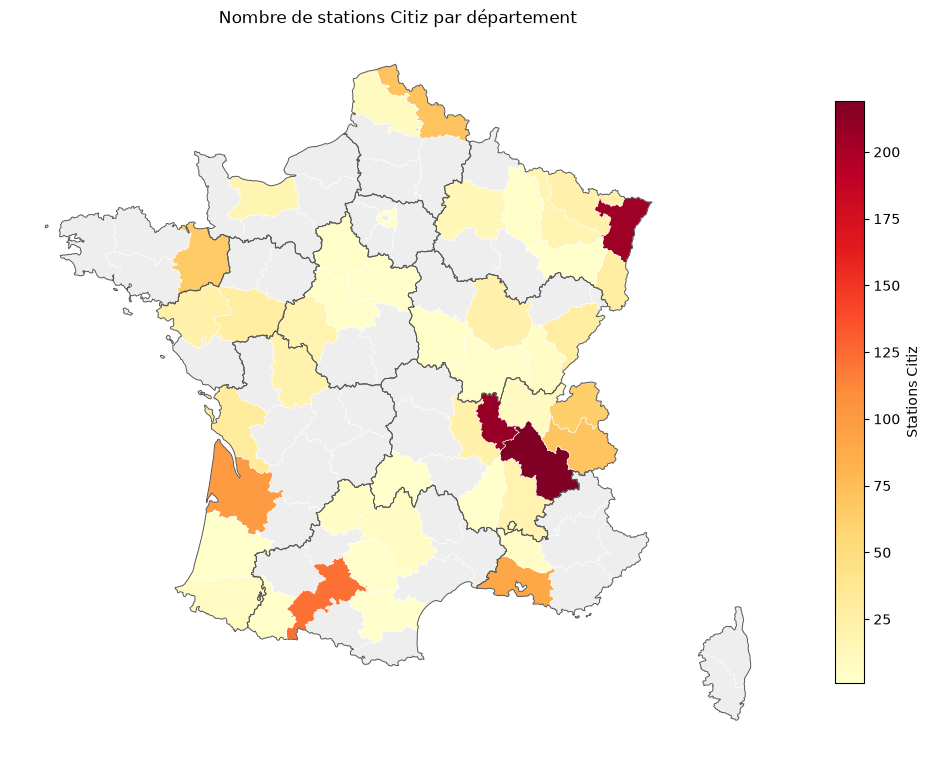

In [8]:
department_counts = departments_l93.merge(by_department[["dep_code", "stations"]],
                                         left_on="code", right_on="dep_code", how="left")
department_counts["stations"] = department_counts.stations.fillna(0)

fig, ax = plt.subplots(figsize=(10, 10))
department_counts[department_counts.stations == 0].plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.4)
department_counts[department_counts.stations > 0].plot(ax=ax, column="stations", cmap="YlOrRd", legend=True,
                                                       edgecolor="white", linewidth=0.4,
                                                       legend_kwds={"label": "Stations Citiz", "shrink": 0.6})
regions_l93.boundary.plot(ax=ax, color="#555", linewidth=0.7)
ax.set_title("Nombre de stations Citiz par département")
ax.set_axis_off()
plt.tight_layout()
fig.savefig(processed_directory / "citiz_stations_by_department.png", dpi=150)
plt.show()

## 6. Export

`citiz_stations_geo.csv` garde les colonnes du fichier déjà partagé avec l'équipe (`reseau`, `dep_code`, `departement`, `region` compris).

In [9]:
located.drop(columns="geometry").to_csv(processed_directory / "citiz_stations_geo.csv", index=False)
saved = pd.read_csv(processed_directory / "citiz_stations_geo.csv", dtype={"dep_code": "string"})
assert saved.station_uid.is_unique and len(saved) == len(stations)
print(f"{len(saved)} stations -> {(processed_directory / 'citiz_stations_geo.csv').relative_to(project_directory)}")

1615 stations -> citiz/data/processed/citiz_stations_geo.csv


## 7. Publier pour l'équipe (optionnel)

`output/citiz_stations_geo.csv` et `output/citiz_flux.csv`, à la racine du dépôt, sont la **référence partagée** lue par `regional-data/`, qui en vérifie l'empreinte. On ne les remplace que volontairement, après accord de l'équipe : passer `PUBLISH_TO_TEAM` à `True` puis relancer cette cellule.

In [10]:
PUBLISH_TO_TEAM = False

if PUBLISH_TO_TEAM:
    shared_directory = project_directory / "output"
    shutil.copy(processed_directory / "citiz_stations_geo.csv", shared_directory / "citiz_stations_geo.csv")
    shutil.copy(gbfs_directory / "citiz_flux.csv", shared_directory / "citiz_flux.csv")
    print("Shared reference updated: tell the team, regional-data must be re-run.")
else:
    print("Shared reference unchanged (PUBLISH_TO_TEAM = False).")

Shared reference unchanged (PUBLISH_TO_TEAM = False).
